# College Majors 2026: Model and Model Comparison (Bachelor's programs)
**BUAN 6341 Group 2 · Sections 3 (Model) and 4 (Model Comparison)**

This notebook continues Jennia's data-preparation notebook (`College_Majors_Bachelors_Data_Prep_EDA.ipynb`).
It reads her output, `bachelors_model_ready.csv`, and uses **her** features, preprocessing and institution-grouped
train/test split unchanged, so the data section and the model section line up.

| | |
|---|---|
| **Target** | `target_log_earnings_4yr`: log of median earnings 4 years after a bachelor's degree |
| **Baseline** | Predict the national median for the program's field (no training), from Jennia's notebook |
| **Models** | Ridge Regression (Lecture 3), Random Forest (Lecture 8), Histogram Gradient Boosting (Lectures 8, 10a) |
| **Tuning** | Grid / randomized search with 5-fold `GroupKFold` by institution on the training set only |
| **Metrics** | MAE and RMSE in dollars, R² on log earnings and on dollars, all on the held-out schools |

> **GenAI disclosure (course policy, Lecture 1):** code and text in this notebook were generated with Claude (Anthropic).

In [1]:
import time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.model_selection import GroupKFold, GridSearchCV, RandomizedSearchCV, cross_val_score
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.inspection import permutation_importance
from pathlib import Path

warnings.filterwarnings('ignore')
RANDOM_STATE = 42
FIG = Path('figures_regression'); FIG.mkdir(exist_ok=True)

## 1. Load Jennia's model-ready data
Same feature lists as her notebook (section 4.2): 25 numeric + 6 categorical features. The optional debt features and the
high-cardinality columns (CIP code, state) stay out, as in her baseline pipeline.

In [2]:
df = pd.read_csv('bachelors_model_ready.csv', dtype={'opeid6': str, 'cip_code_4digit': str})
NUMERIC = ['log_awards_avg', 'is_main_campus', 'outcomes_shared_across_campuses', 'log_enrollment',
           'institution_tuition_in_state_usd', 'tuition_out_minus_in', 'institution_admission_rate',
           'admission_rate_missing', 'institution_avg_sat', 'sat_missing', 'institution_is_hbcu',
           'institution_latitude', 'institution_longitude', 'national_median_earnings_4yr_usd',
           'linked_occupations_count', 'occupation_median_wage_2024_usd', 'occupation_growth_pct_2024_34',
           'occupation_growth_pct_max', 'log_occ_employment', 'occupations_using_ai_software',
           'ai_software_occupation_share', 'expert_system_occupation_share', 'ai_tools_max_per_occupation',
           'hot_technologies_mean_per_occupation', 'any_ai_occupation']
CATEGORICAL = ['institution_control', 'institution_region', 'cip_family_title', 'online', 'selectivity',
               'occupation_typical_entry_education']
TARGET, GROUP = 'target_log_earnings_4yr', 'opeid6'

train, test = df[df.split == 'train'], df[df.split == 'test']
X_tr, y_tr, g_tr = train[NUMERIC + CATEGORICAL], train[TARGET], train[GROUP]
X_te, y_te = test[NUMERIC + CATEGORICAL], test[TARGET]
dollars_te = test['median_earnings_4yr_usd']
print(f'Train: {len(train):,} programs, {g_tr.nunique():,} schools | Test: {len(test):,} programs, {test[GROUP].nunique():,} schools')
print('Schools in both sets:', len(set(g_tr) & set(test[GROUP])))

Train: 19,932 programs, 1,439 schools | Test: 5,351 programs, 360 schools
Schools in both sets: 0


## 2. Shared preprocessing (Jennia's pipeline)
Median imputation and scaling for numeric features, one-hot encoding for categoricals, fit on training folds only.
The one-hot output is dense because Histogram Gradient Boosting does not accept sparse input.

In [3]:
pre = ColumnTransformer([
    ('num', Pipeline([('impute', SimpleImputer(strategy='median')), ('scale', StandardScaler())]), NUMERIC),
    ('cat', OneHotEncoder(handle_unknown='ignore', min_frequency=30, sparse_output=False), CATEGORICAL)])
cv = GroupKFold(n_splits=5)

def evaluate(name, log_pred, cv_mae=None):
    dollars_pred = np.exp(log_pred)
    return {'Model': name,
            'CV MAE (log)': cv_mae,
            'Test MAE ($)': mean_absolute_error(dollars_te, dollars_pred),
            'Test RMSE ($)': mean_squared_error(dollars_te, dollars_pred) ** 0.5,
            'Test R² (log)': r2_score(y_te, log_pred),
            'Test R² ($)': r2_score(dollars_te, dollars_pred)}

rows, preds, searches = [], {}, {}

## 3. Baseline: the field's national median
No model: predict that every program earns its field's national median. Every model has to beat this.

In [4]:
base = np.log(test['national_median_earnings_4yr_usd'])
rows.append(evaluate('Baseline: national field median', base)); preds['Baseline'] = base
pd.DataFrame(rows).round(3)

,Model,CV MAE (log),Test MAE ($),Test RMSE ($),Test R² (log),Test R² ($)
0,Baseline: national field median,None,8760.366,12624.187,0.566,0.587


## 4. Models and tuning
Each model is put behind the same preprocessing and tuned on the training set only, with 5 institution-grouped folds and
MAE on log earnings as the selection score. For every model we also record the **untuned default** CV score, so we can
say how much tuning helped.

In [5]:
def tune(name, model, grid, search='random', n_iter=12):
    pipe = Pipeline([('pre', pre), ('model', model)])
    t = time.time()
    default = -cross_val_score(pipe, X_tr, y_tr, groups=g_tr, cv=cv, scoring='neg_mean_absolute_error', n_jobs=-1).mean()
    S = (GridSearchCV(pipe, grid) if search == 'grid'
         else RandomizedSearchCV(pipe, grid, n_iter=n_iter, random_state=RANDOM_STATE))
    S.set_params(cv=cv, scoring='neg_mean_absolute_error', n_jobs=-1)
    S.fit(X_tr, y_tr, groups=g_tr)
    print(f'{name}: default CV MAE = {default:.4f} -> tuned CV MAE = {-S.best_score_:.4f}  ({time.time() - t:.0f}s)')
    print('   best params:', {k.replace('model__', ''): v for k, v in S.best_params_.items()})
    S.default_cv_mae = default
    return S

### 4.1 Ridge Regression (Lecture 3)
Linear regression with an L2 penalty that shrinks coefficients. `alpha` sets the penalty strength: larger alpha means
more shrinkage. We grid-search 13 values from 0.001 to 1000.

In [6]:
searches['Ridge Regression'] = tune('Ridge', Ridge(), {'model__alpha': np.logspace(-3, 3, 13)}, search='grid')

Ridge: default CV MAE = 0.1120 -> tuned CV MAE = 0.1120  (7s)
   best params: {'alpha': np.float64(3.1622776601683795)}


### 4.2 Random Forest (Lecture 8, bagging)
Many deep trees, each trained on a bootstrap sample and a random subset of features at each split, then averaged.
Tuned: number of trees, depth, minimum leaf size and features per split.

In [7]:
searches['Random Forest'] = tune('RF', RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=1),
    {'model__n_estimators': [200, 400], 'model__max_depth': [None, 20, 30],
     'model__min_samples_leaf': [1, 3, 5, 10], 'model__max_features': ['sqrt', 0.3, 0.5]}, n_iter=10)

RF: default CV MAE = 0.1037 -> tuned CV MAE = 0.1015  (83s)
   best params: {'n_estimators': 200, 'min_samples_leaf': 3, 'max_features': 0.5, 'max_depth': None}


### 4.3 Histogram Gradient Boosting (Lectures 8 and 10a)
Gradient boosting adds small trees one after another, each fitted to the remaining errors and scaled by the learning rate.
**Extension of the class model:** before splitting, every feature is grouped into at most 255 bins (a histogram), so the
model searches far fewer split points. This is the same histogram idea as XGBoost's `tree_method='hist'` from Lecture 10a,
and it makes training fast on 20,000 rows.
Tuned: learning rate, number of boosting rounds, tree size (`max_leaf_nodes`), minimum leaf size and the L2 penalty.

In [8]:
searches['Hist Gradient Boosting'] = tune('HGB', HistGradientBoostingRegressor(random_state=RANDOM_STATE, early_stopping=False),
    {'model__learning_rate': [0.03, 0.05, 0.1], 'model__max_iter': [300, 600, 1000],
     'model__max_leaf_nodes': [15, 31, 63], 'model__min_samples_leaf': [20, 50],
     'model__l2_regularization': [0.0, 1.0]}, n_iter=12)

HGB: default CV MAE = 0.1036 -> tuned CV MAE = 0.1021  (101s)
   best params: {'min_samples_leaf': 20, 'max_leaf_nodes': 31, 'max_iter': 600, 'learning_rate': 0.03, 'l2_regularization': 1.0}


## 5. Model comparison on the held-out schools
Predictions are made on the log scale and converted back to dollars (`exp`) for MAE and RMSE, so errors read in dollars.

In [9]:
for name, S in searches.items():
    p = S.predict(X_te); preds[name] = p
    rows.append(evaluate(name, p, -S.best_score_))
results = pd.DataFrame(rows).set_index('Model')
results = pd.concat([results.iloc[:1], results.iloc[1:].sort_values('Test MAE ($)')])
results.to_csv('regression_model_comparison.csv')
results.round({'CV MAE (log)': 4, 'Test MAE ($)': 0, 'Test RMSE ($)': 0, 'Test R² (log)': 3, 'Test R² ($)': 3})

,CV MAE (log),Test MAE ($),Test RMSE ($),Test R² (log),Test R² ($)
Model,,,,,
Baseline: national field median,NaN,8760.0,12624.0,0.566,0.587
Random Forest,0.1015,6226.0,8886.0,0.787,0.795
Hist Gradient Boosting,0.1021,6341.0,8974.0,0.780,0.791
Ridge Regression,0.1120,7030.0,10005.0,0.744,0.741


In [10]:
tuning = pd.DataFrame({'Default CV MAE (log)': {n: S.default_cv_mae for n, S in searches.items()},
                       'Tuned CV MAE (log)': {n: -S.best_score_ for n, S in searches.items()},
                       'Best settings': {n: {k.replace('model__', ''): v for k, v in S.best_params_.items()} for n, S in searches.items()}})
tuning.round(4)

,Default CV MAE (log),Tuned CV MAE (log),Best settings
Ridge Regression,0.1120,0.1120,{'alpha': 3.1622776601683795}
Random Forest,0.1037,0.1015,"{'n_estimators': 200, 'min_samples_leaf': 3, '..."
Hist Gradient Boosting,0.1036,0.1021,"{'min_samples_leaf': 20, 'max_leaf_nodes': 31,..."


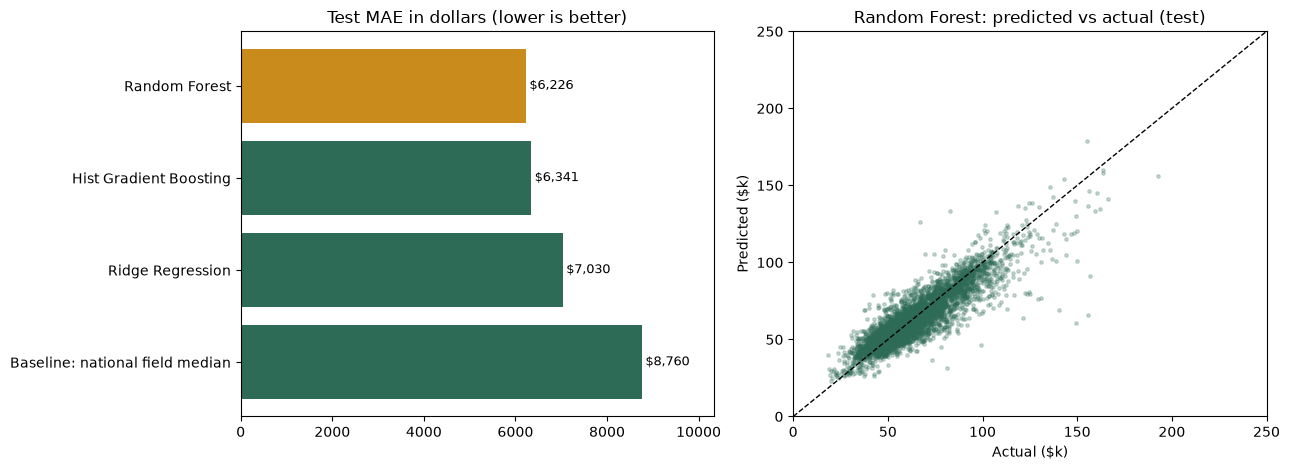

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.8))
r = results.sort_values('Test MAE ($)', ascending=False)
ax[0].barh(r.index, r['Test MAE ($)'], color=['#C98B1B' if i == len(r) - 1 else '#2E6B57' for i in range(len(r))])
for y, v in enumerate(r['Test MAE ($)']): ax[0].text(v + 80, y, f'${v:,.0f}', va='center', fontsize=9)
ax[0].set_title('Test MAE in dollars (lower is better)'); ax[0].set_xlim(0, r['Test MAE ($)'].max() * 1.18)
best_name = results.iloc[1:].index[0]
ax[1].scatter(dollars_te / 1000, np.exp(preds[best_name]) / 1000, s=6, alpha=.25, color='#2E6B57')
lim = [0, 250]; ax[1].plot(lim, lim, 'k--', lw=1); ax[1].set_xlim(lim); ax[1].set_ylim(lim)
ax[1].set(title=f'{best_name}: predicted vs actual (test)', xlabel='Actual ($k)', ylabel='Predicted ($k)')
plt.tight_layout(); plt.savefig(FIG / 'model_comparison.png', dpi=150); plt.show()

### 5.1 What drives the best model? (permutation importance on the test set)

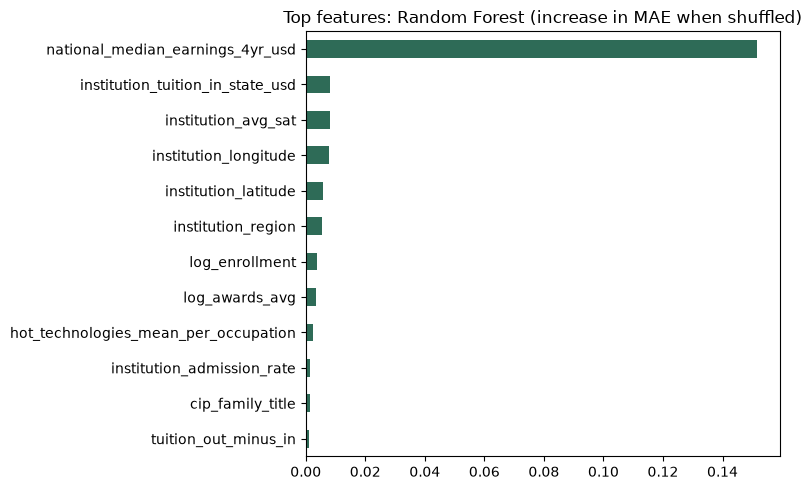

In [12]:
best = searches[best_name].best_estimator_
pi = permutation_importance(best, X_te, y_te, scoring='neg_mean_absolute_error', n_repeats=5,
                            random_state=RANDOM_STATE, n_jobs=-1)
imp = pd.Series(pi.importances_mean, index=X_te.columns).sort_values(ascending=False)
imp.to_csv('regression_permutation_importance.csv')
imp.head(12)[::-1].plot.barh(figsize=(8, 5), color='#2E6B57', title=f'Top features: {best_name} (increase in MAE when shuffled)')
plt.tight_layout(); plt.savefig(FIG / 'feature_importance.png', dpi=150); plt.show()

## 6. Takeaways for the Conclusion
- Read the comparison table: every model should beat the national-field-median baseline; the gap is the value the models add.
- CV and test errors should be close, which shows the institution-grouped split keeps the test honest.
- The permutation-importance chart shows which inputs matter beyond the field benchmark.